# Практическая работа №1. Фильтрация изображений с использованием свёртки в Python

**Цель работы:** изучение метода 2D-свёртки изображений с использованием функции `cv2.filter2D()` библиотеки OpenCV, применение фильтров низких и высоких частот, а также разработка собственных ядер свёртки для решения прикладных задач.

**Инструменты:** Python 3.7+, OpenCV (`opencv-python`), NumPy, Matplotlib.

---

### Содержание
1. Установка библиотек и импорты
2. Задача 1. Применение фильтров низких и высоких частот ко всем растрам
3. Задача 2. Сравнение результатов и выводы
4. Задача 3. Собственные параметры ядра свёртки
5. Задача 4. Итоговый отчёт

## 1. Установка библиотек и импорты

In [1]:
!pip install numpy opencv-python matplotlib -q


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Папки для входных и выходных изображений
INPUT_DIR = "Изображения"
OUTPUT_DIR = "Результаты"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("OpenCV version:", cv2.__version__)
print("Папка с исходниками:", os.path.abspath(INPUT_DIR))
print("Файлы в папке:", os.listdir(INPUT_DIR))

OpenCV version: 5.0.0
Папка с исходниками: d:\Python\image_processing\1b\Изображения
Файлы в папке: ['1.JPG', '2.jpg', '3.jpg', '4.jpg', '5.JPG']


## Вспомогательные функции

Так как папка называется по-русски (`Изображения`), стандартный `cv2.imread` на Windows может «молча» вернуть `None` из-за не-ASCII символов в пути. Поэтому используются юникод-совместимые обёртки через `np.fromfile` + `cv2.imdecode`.

- `imread_unicode(path, flags)` — читает изображение по пути с не-ASCII символами.
- `imwrite_unicode(path, img)` — сохраняет изображение по пути с не-ASCII символами.
- `apply_filter(img, kernel, mode)` — применяет свёртку с нормализацией ядра (как в методичке). Режим `mode="abs"` нужен для ядер с суммой 0 (детекторы границ): свёртка считается во float32 и берётся модуль отклика, иначе при записи в `uint8` все отрицательные значения обрезаются до 0 и теряется половина границ.
- `show_pair(src, dst, ...)` — отображает исходное и обработанное изображения рядом.

In [3]:
def imread_unicode(path, flags=cv2.IMREAD_COLOR):
    """Читает изображение по пути с не-ASCII символами (Windows/Linux/macOS)."""
    arr = np.fromfile(path, dtype=np.uint8)
    if arr.size == 0:
        return None
    return cv2.imdecode(arr, flags)


def imwrite_unicode(path, img):
    """Сохраняет изображение по пути с не-ASCII символами."""
    ext = os.path.splitext(path)[1]
    ok, buf = cv2.imencode(ext, img)
    if not ok:
        return False
    buf.tofile(path)
    return True


def apply_filter(img, kernel, mode="clip"):
    """Применяет свёртку cv2.filter2D с нормализацией ядра (как в методичке).

    mode="clip" — результат сразу в uint8 (отрицательные значения -> 0, >255 -> 255);
    mode="abs"  — свёртка во float32, затем модуль отклика и обрезка в 0..255.
                  Нужен для ядер с суммой 0 (градиенты), чтобы видеть границы обоих знаков.
    """
    kernel = np.asarray(kernel, dtype=np.float32)
    s = kernel.sum()
    if not np.isclose(s, 0):
        kernel = kernel / s
    if mode == "clip":
        return cv2.filter2D(img, -1, kernel)
    if mode == "abs":
        res = cv2.filter2D(img.astype(np.float32), -1, kernel)
        return np.clip(np.abs(res), 0, 255).astype(np.uint8)
    raise ValueError("mode должен быть 'clip' или 'abs'")


def show_pair(src, dst, title_src="Source", title_dst="Result"):
    """Отображает исходное и обработанное изображения рядом."""
    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(src, cv2.COLOR_BGR2RGB))
    plt.title(title_src)
    plt.axis("off")
    plt.subplot(1, 2, 2)
    plt.imshow(cv2.cvtColor(dst, cv2.COLOR_BGR2RGB))
    plt.title(title_dst)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

## 2. Задача 1. Применение фильтров высоких и низких частот

**Требуется:** применить ко всем растрам из папки «Изображения» фильтры высоких и низких частот, сохранить обработанные изображения.

Используем классические ядра из методички:
- **Low-pass** — усредняющее ядро 5×5 из единиц (нормируется на сумму).
- **High-pass** — лапласиан 3×3 (`[[0,-1,0],[-1,4,-1],[0,-1,0]]`).

In [4]:
# Ядра по умолчанию из методички
kernel_low = np.ones((5, 5), dtype=np.float32)                   # низкочастотный
kernel_high = np.array([[0., -1., 0.],
                        [-1., 4., -1.],
                        [0., -1., 0.]], dtype=np.float32)        # высокочастотный

print("Low-pass kernel (5x5):")
print(kernel_low)
print("\nHigh-pass kernel (3x3):")
print(kernel_high)

Low-pass kernel (5x5):
[[1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]]

High-pass kernel (3x3):
[[ 0. -1.  0.]
 [-1.  4. -1.]
 [ 0. -1.  0.]]


### Диагностика: проверка чтения файлов

Проверим, что все файлы корректно читаются юникод-совместимой обёрткой.

In [5]:
for fname in sorted(os.listdir(INPUT_DIR)):
    if not fname.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".tif")):
        continue
    path = os.path.join(INPUT_DIR, fname)
    size = os.path.getsize(path)
    with open(path, "rb") as f:
        head = f.read(4).hex().upper()
    img = imread_unicode(path)
    status = "OK" if img is not None else "FAIL"
    shape = img.shape if img is not None else "-"
    print(f"{fname:10s} size={size:>10}  head={head}  read={status}  shape={shape}")

1.JPG      size=    689903  head=FFD8FFE0  read=OK  shape=(1024, 1536, 3)
2.jpg      size=    973921  head=FFD8FFE1  read=OK  shape=(1065, 1600, 3)
3.jpg      size=   1567642  head=FFD8FFE0  read=OK  shape=(2097, 2560, 3)
4.jpg      size=    456749  head=FFD8FFDB  read=OK  shape=(785, 1240, 3)
5.JPG      size=  12942321  head=FFD8FFE0  read=OK  shape=(3507, 4960, 3)


### Обработка всех изображений

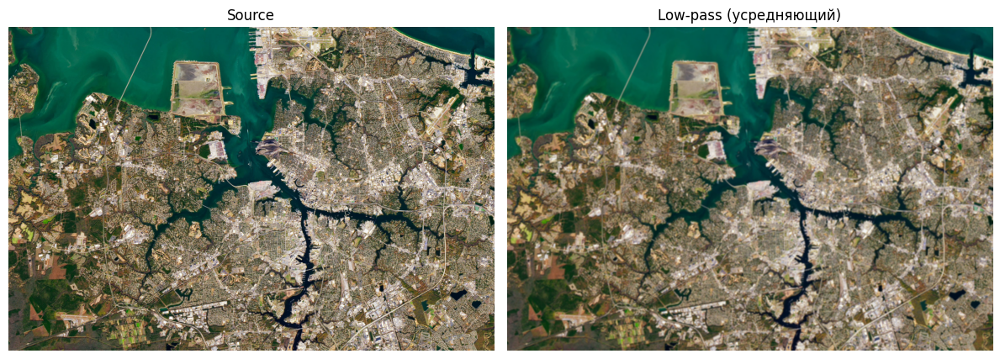

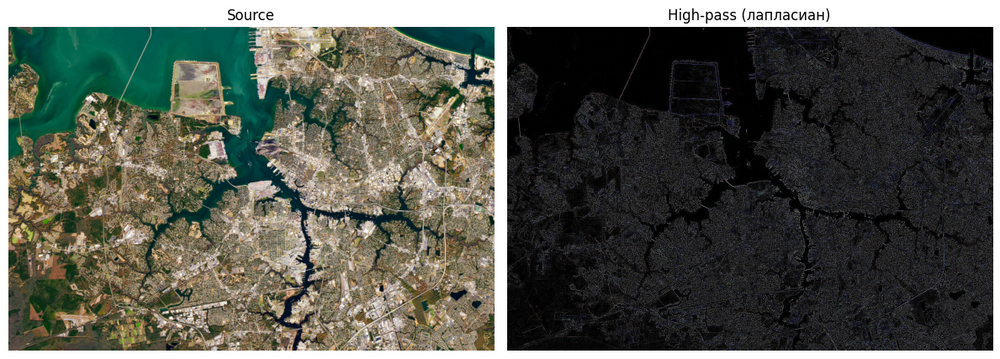

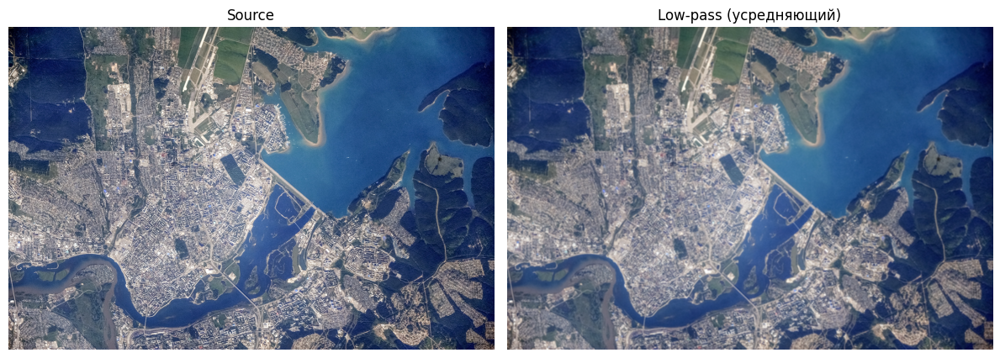

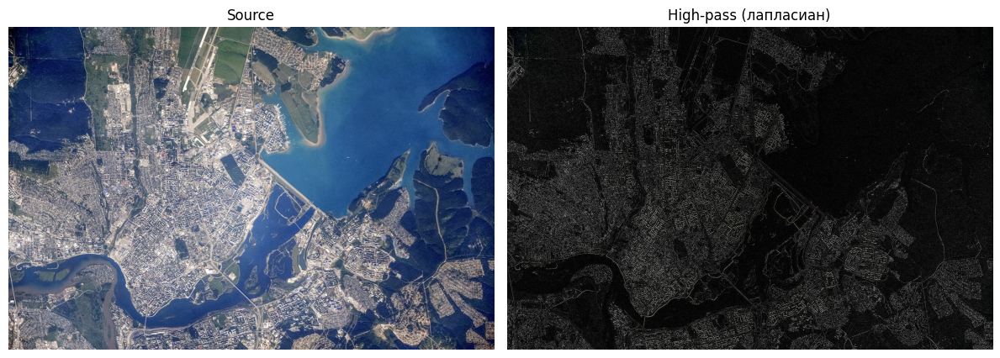

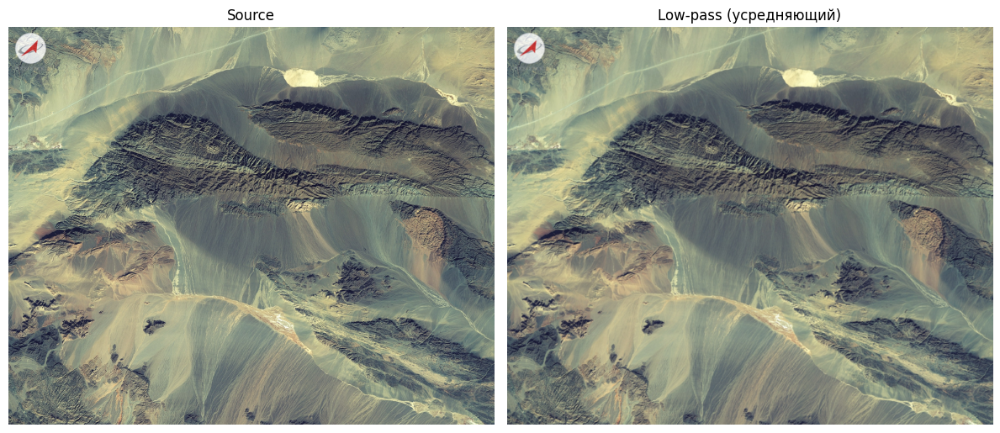

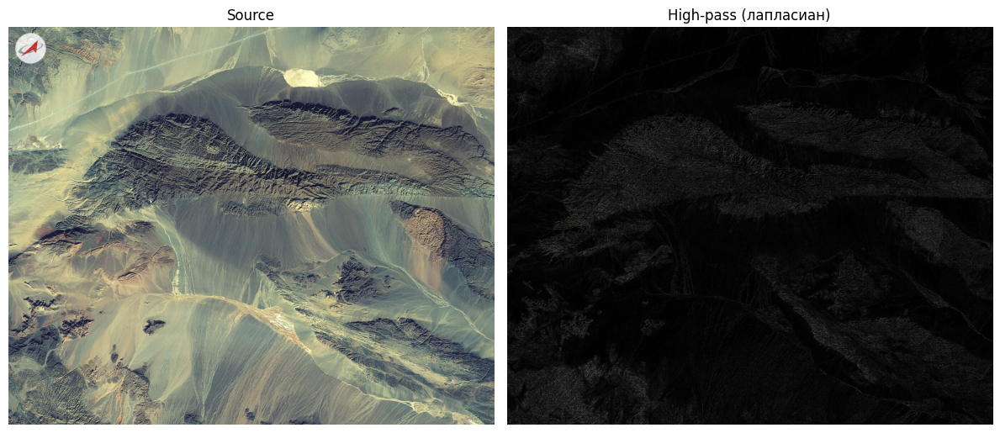

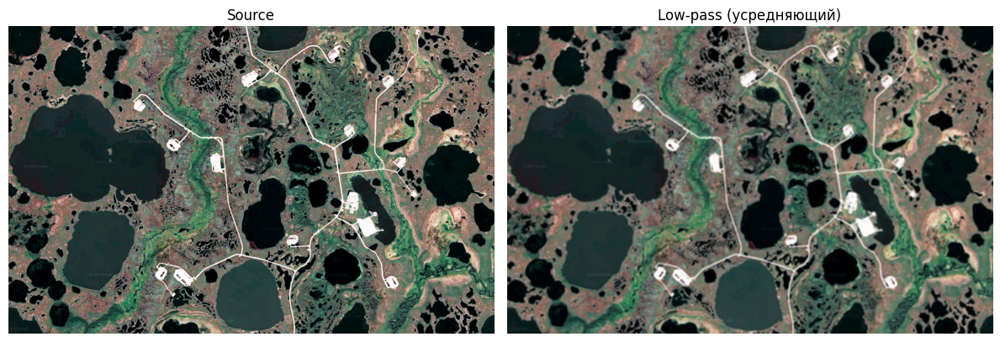

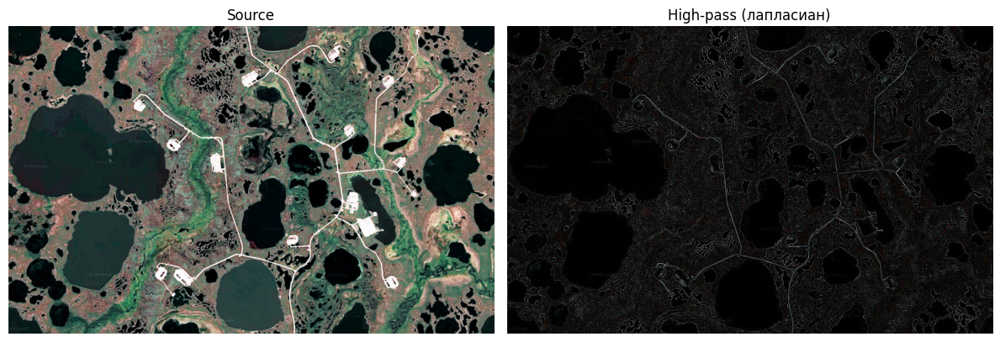

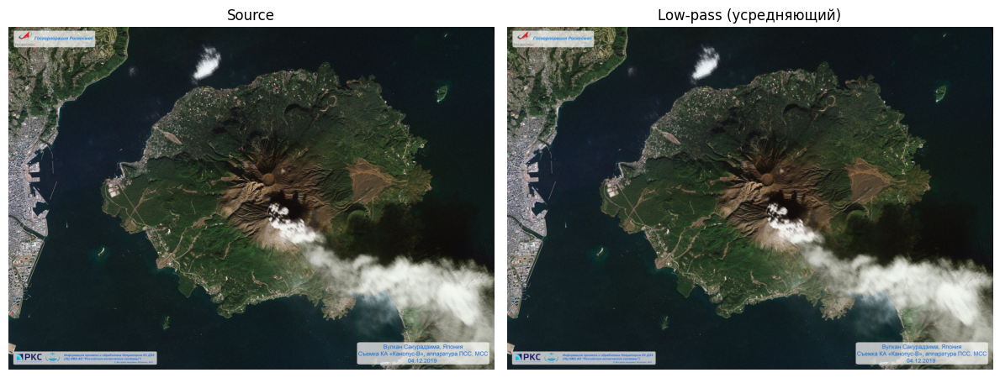

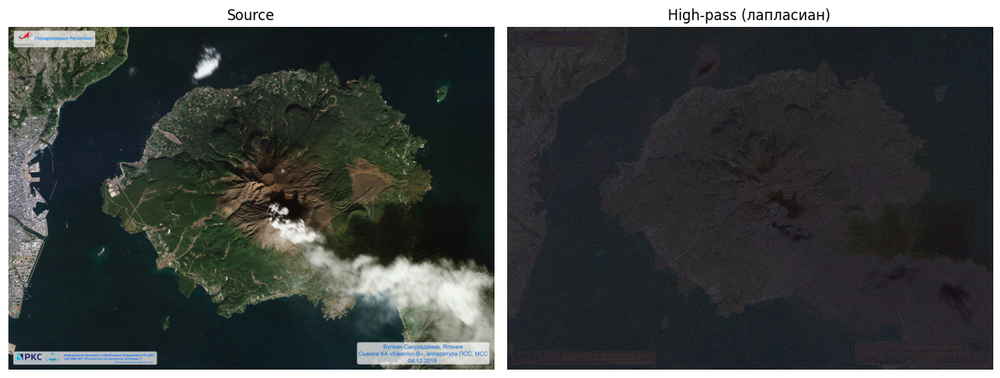

Обработано изображений: 5
Результаты сохранены в папку: Результаты


In [6]:
processed_count = 0

for fname in sorted(os.listdir(INPUT_DIR)):
    if not fname.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".tif")):
        continue
    path = os.path.join(INPUT_DIR, fname)
    img = imread_unicode(path, cv2.IMREAD_COLOR)
    if img is None:
        print(f"[skip] Не удалось прочитать: {fname}")
        continue

    low  = apply_filter(img, kernel_low)
    high = apply_filter(img, kernel_high)

    base, _ = os.path.splitext(fname)
    imwrite_unicode(os.path.join(OUTPUT_DIR, f"{base}_low.jpg"),  low)
    imwrite_unicode(os.path.join(OUTPUT_DIR, f"{base}_high.jpg"), high)

    show_pair(img, low,  "Source", "Low-pass (усредняющий)")
    show_pair(img, high, "Source", "High-pass (лапласиан)")

    processed_count += 1

print(f"Обработано изображений: {processed_count}")
print(f"Результаты сохранены в папку: {OUTPUT_DIR}")

### Увеличенные фрагменты «до/после»

Снимки большие (от 1240 до 4960 пикселей по ширине), поэтому на общем виде действие ядра 5×5 почти незаметно. Для сравнения выведем по каждому снимку фрагмент 400×400 пикселей в исходном масштабе.

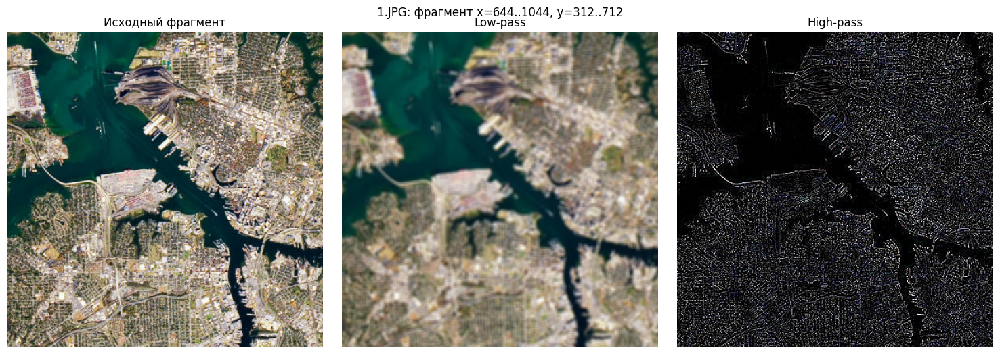

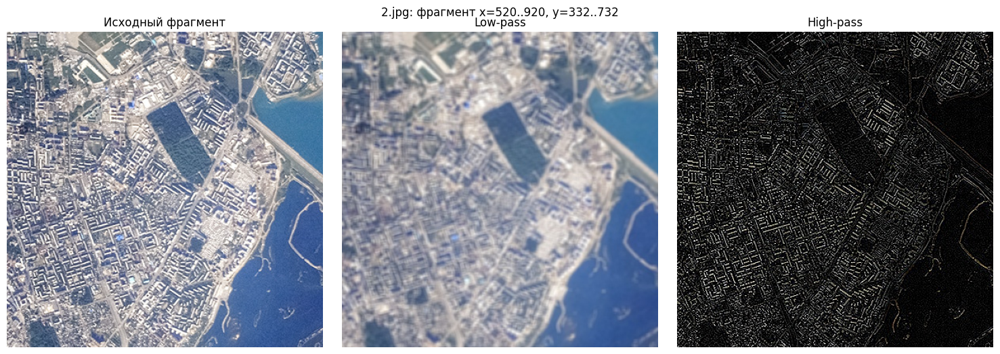

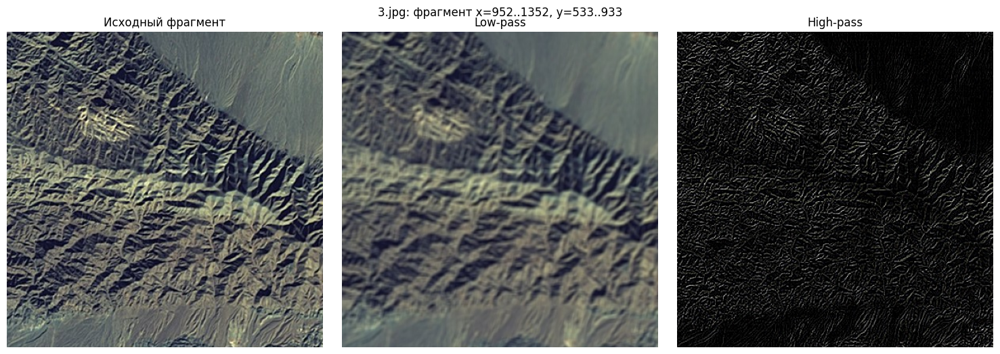

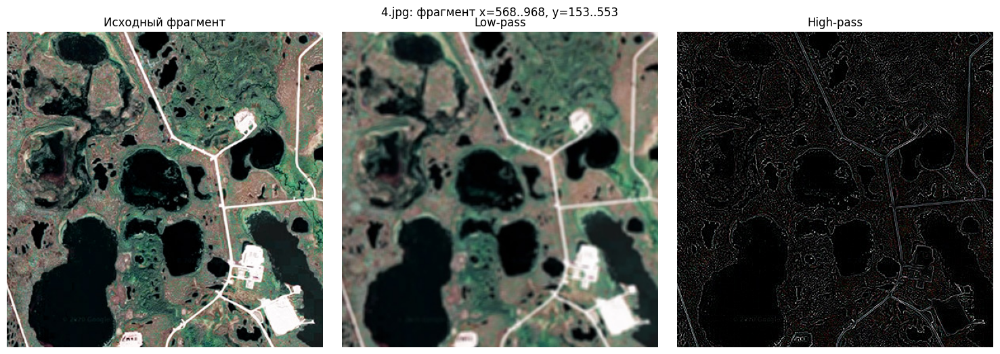

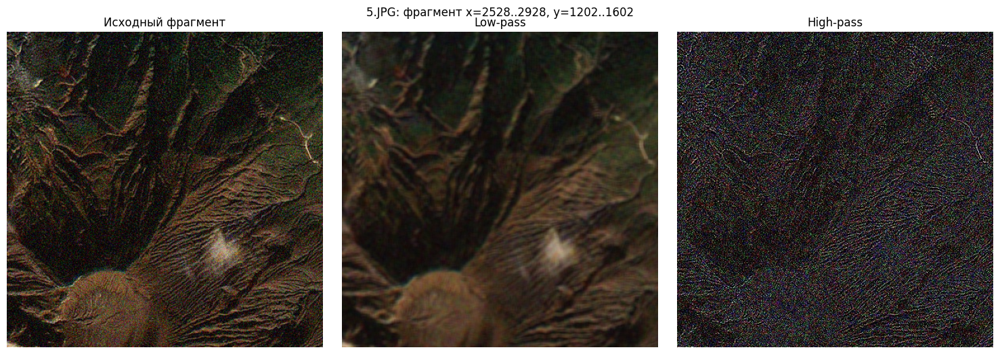

In [7]:
# Центры фрагментов (доли ширины и высоты) — выбраны на участках с характерными объектами
crop_centers = {"1.JPG": (0.55, 0.50), "2.jpg": (0.45, 0.50), "3.jpg": (0.45, 0.35),
                "4.jpg": (0.62, 0.45), "5.JPG": (0.55, 0.40)}
CROP = 400

for fname, (cx, cy) in crop_centers.items():
    src = imread_unicode(os.path.join(INPUT_DIR, fname))
    base = os.path.splitext(fname)[0]
    low = imread_unicode(os.path.join(OUTPUT_DIR, f"{base}_low.jpg"))
    high = imread_unicode(os.path.join(OUTPUT_DIR, f"{base}_high.jpg"))
    h, w = src.shape[:2]
    y0 = int(np.clip(cy * h - CROP // 2, 0, h - CROP))
    x0 = int(np.clip(cx * w - CROP // 2, 0, w - CROP))
    sl = (slice(y0, y0 + CROP), slice(x0, x0 + CROP))

    fig, ax = plt.subplots(1, 3, figsize=(15, 5.3))
    for a, im, t in zip(ax, (src, low, high), ("Исходный фрагмент", "Low-pass", "High-pass")):
        a.imshow(cv2.cvtColor(im[sl], cv2.COLOR_BGR2RGB))
        a.set_title(t)
        a.axis("off")
    fig.suptitle(f"{fname}: фрагмент x={x0}..{x0 + CROP}, y={y0}..{y0 + CROP}")
    plt.tight_layout()
    plt.show()

## 3. Задача 2. Сравнение «до/после» и выводы

### Описание по каждому снимку

| Снимок | Low-pass (усреднение 5×5) | High-pass (лапласиан 3×3) | Наиболее выраженные объекты |
|---|---|---|---|
| **1.JPG** — прибрежный город, залив и разветвлённые протоки | Мелкая застройка и отдельные дома сливаются в однородные пятна, тонкие дороги и причалы размываются; акватория, поля и лесные массивы почти не меняются. | Вода и однородные поля становятся чёрными; ярко проступают кварталы застройки, сетка дорог, железнодорожные пути, причалы и береговая линия проток. | Low: водная поверхность, крупные массивы. High: застройка, дороги, береговая линия. |
| **2.jpg** — город на берегу залива и реки | Городская застройка теряет структуру, улицы перестают читаться; залив, река и лес остаются почти прежними. | Залив и река — тёмные; светлыми выделяются кварталы, улицы, аэродром с полосами, мосты и берега. Плотность застройки читается по яркости отклика. | Low: залив, река, лес. High: улицы, кварталы, аэродром, мосты. |
| **3.jpg** — горные хребты и предгорья | Размываются мелкие осыпи и складки рельефа, остаются крупные формы: хребты, долины, тени склонов. | Почти весь снимок тёмный (рельеф плавный); отклик есть на скальных гребнях, оврагах, руслах и на тонкой дороге. | Low: крупные формы рельефа. High: гребни хребтов, овраги, линейные объекты. |
| **4.jpg** — тундра с озёрами, дороги и площадки | Озёра и болотные участки остаются чёткими пятнами, тонкие дороги становятся бледнее и шире, мелкая текстура тундры исчезает. | Наиболее информативный результат: светлыми линиями выделяются дороги, контуры площадок и сооружений, берега озёр; поверхность озёр — чёрная. | Low: озёра, болота. High: дороги, площадки, берега озёр. |
| **5.JPG** — вулкан Сакурадзима, залив, облака | Сглаживаются шумы на воде и текстура леса; кратер, облака и береговая линия остаются различимы как крупные объекты. | Сильно проявляется зерно (шум, JPEG-артефакты) на воде и по всему снимку; выделяются кромка острова, кратер, застройка и порт на соседнем берегу, а также подписи в углах. | Low: остров, облака, залив. High: береговая линия, кратер, застройка; одновременно усиливается шум. |

### Общие наблюдения

| Фильтр | Что происходит с изображением | Какие объекты выделяются |
|---|---|---|
| **Low-pass (усреднение 5×5)** | Соседние пиксели усредняются с одинаковыми весами. Изображение становится более гладким, шум и мелкие детали подавляются. На крупных снимках эффект заметен только при увеличении. | Хорошо проявляются **крупные однородные области**: водная поверхность, лесные массивы, поля, крупные формы рельефа. Мелкие объекты (дома, тонкие дороги) размываются. |
| **High-pass (лапласиан 3×3)** | Остаются только перепады яркости, однородные области становятся чёрными. Так как сумма ядра равна 0 и результат записывается в `uint8`, отрицательные значения обрезаются до 0 — видна только «светлая» сторона каждой границы. | Ярко выражены **линейные и мелкие объекты**: дороги, улицы, застройка, береговые линии, гребни. Вместе с ними усиливается и **шум**. |

### Общий вывод

- **Фильтры низких частот** — инструмент **сглаживания и шумоподавления**. Применяются:
  - перед бинаризацией и OCR (убрать зернистость сканирования);
  - для подавления шума перед выделением крупных объектов (водоёмов, массивов леса, полей);
  - для художественного размытия.
- **Фильтры высоких частот** — инструмент **выделения границ и деталей**. Применяются:
  - для выделения контуров и линейных объектов (дороги, береговые линии, границы участков);
  - как составная часть повышения резкости (ядро из методички с центром 5 = исходное изображение + лапласиан);
  - для анализа текстуры и поиска дефектов.
- Высокочастотный фильтр усиливает и шум, поэтому на зашумлённых снимках (как 5.JPG) его лучше применять после предварительного сглаживания.

## 4. Задача 3. Собственные параметры ядра свёртки

Разработаем и протестируем **7 пользовательских ядер** для различных прикладных задач. Для наглядности используем фрагмент снимка `4.jpg`: на нём есть дороги разных направлений, прямоугольные площадки и озёра.

Ядра 1–4 имеют сумму 0 (детекторы границ), поэтому применяются в режиме `mode="abs"`: берётся модуль отклика, и выделяются обе стороны каждой границы.

In [8]:
# =========================================================
# 1) Вертикальные границы — оператор Собеля по X
#    (производная по горизонтали: реагирует на перепады яркости слева направо)
# =========================================================
kernel_vertical = np.array([[-1, 0, 1],
                            [-2, 0, 2],
                            [-1, 0, 1]], dtype=np.float32) * 0.25

# =========================================================
# 2) Горизонтальные границы — оператор Собеля по Y
#    (производная по вертикали: реагирует на перепады яркости сверху вниз)
# =========================================================
kernel_horizontal = np.array([[-1, -2, -1],
                              [ 0,  0,  0],
                              [ 1,  2,  1]], dtype=np.float32) * 0.25

# =========================================================
# 3) Диагональные границы — Собель, повёрнутый на 45°
#    Градиент направлен вверх-вправо, поэтому сильнее всего выделяются
#    границы, идущие по диагонали «\» (из левого верхнего угла в правый нижний)
# =========================================================
kernel_diag45 = np.array([[ 0,  1,  2],
                          [-1,  0,  1],
                          [-2, -1,  0]], dtype=np.float32) * 0.25

# =========================================================
# 4) Оператор Превитта: Gx и Gy, итог — модуль градиента sqrt(Gx² + Gy²)
#    (одно ядро Gx выделяет только вертикальные границы;
#     для «универсального» детектора нужны оба направления)
# =========================================================
kernel_prewitt_x = np.array([[-1, 0, 1],
                             [-1, 0, 1],
                             [-1, 0, 1]], dtype=np.float32) / 3.0
kernel_prewitt_y = kernel_prewitt_x.T


def prewitt_magnitude(img):
    gx = cv2.filter2D(img.astype(np.float32), -1, kernel_prewitt_x)
    gy = cv2.filter2D(img.astype(np.float32), -1, kernel_prewitt_y)
    return np.clip(cv2.magnitude(gx, gy), 0, 255).astype(np.uint8)

# =========================================================
# 5) Повышение резкости с регулируемой силой alpha:
#    результат = исходное + alpha * (8·центр − сумма 8 соседей)
#    Сумма ядра всегда 1, яркость сохраняется. alpha=1 — классическое ядро с центром 9.
# =========================================================
def sharpening_kernel(alpha=1.0):
    k = -alpha * np.ones((3, 3), dtype=np.float32)
    k[1, 1] = 1 + 8 * alpha
    return k

# =========================================================
# 6) Тиснение (emboss). Сумма ядра = 1, поэтому яркость сохраняется
#    и сдвиг +128 не нужен
# =========================================================
kernel_emboss = np.array([[-2, -1, 0],
                          [-1,  1, 1],
                          [ 0,  1, 2]], dtype=np.float32)

# =========================================================
# 7) «Центр–окружение» 5×5: усиление мелких деталей и точечных объектов
#    Центр и ближнее кольцо положительные, внешнее кольцо отрицательное.
#    Ядро симметрично при повороте на 90°, поэтому одинаково реагирует на
#    края и углы любой ориентации — это НЕ детектор углов.
#    Сумма = 8, после нормировки: центр 1, ближнее кольцо 0.25, внешнее −0.125.
# =========================================================
kernel_center_surround = np.array([[-1, -1, -1, -1, -1],
                                   [-1,  2,  2,  2, -1],
                                   [-1,  2,  8,  2, -1],
                                   [-1,  2,  2,  2, -1],
                                   [-1, -1, -1, -1, -1]], dtype=np.float32)

print("Собственные ядра заданы.")

Собственные ядра заданы.


In [9]:
# Тестовое изображение: фрагмент снимка 4.jpg (дороги, площадки, озёра)
test_path = os.path.join(INPUT_DIR, "4.jpg")
img_full = imread_unicode(test_path, cv2.IMREAD_COLOR)
assert img_full is not None, f"Не удалось прочитать {test_path}"

img = img_full[150:650, 600:1100]
print("Тестовое изображение:", test_path)
print("Размер исходника:", img_full.shape, " размер фрагмента:", img.shape)

Тестовое изображение: Изображения\4.jpg
Размер исходника: (785, 1240, 3)  размер фрагмента: (500, 500, 3)


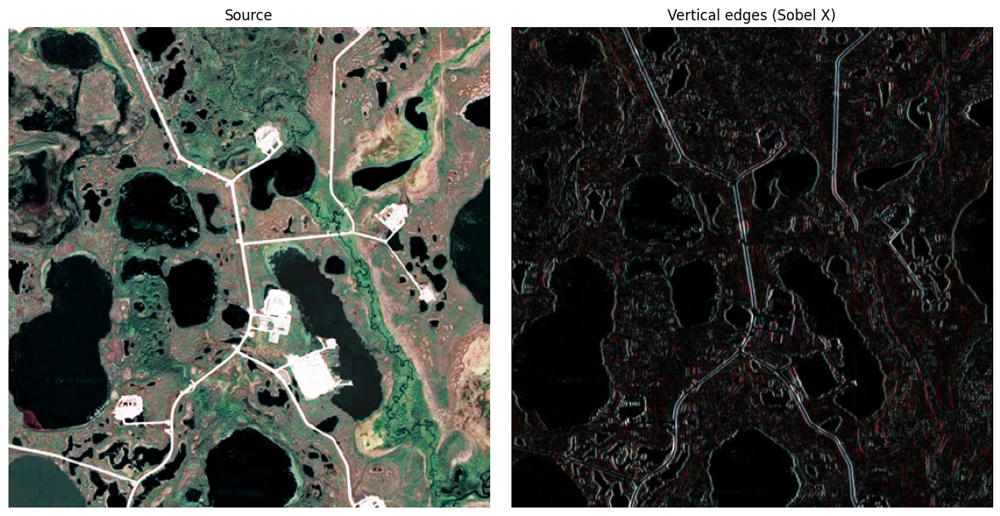

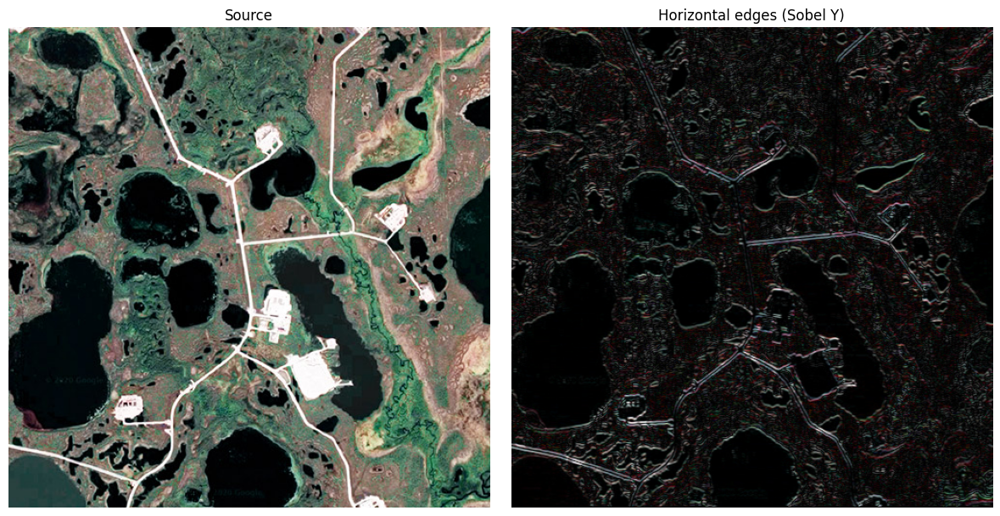

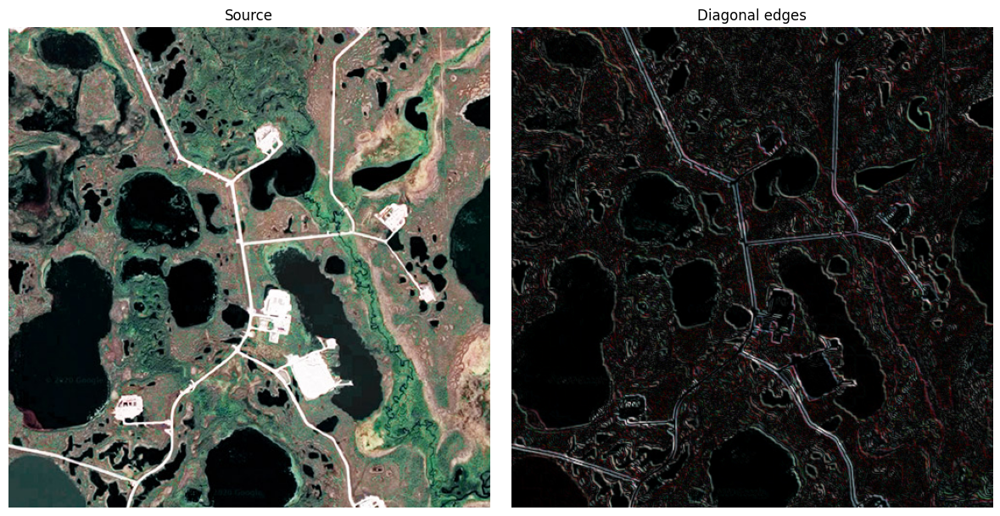

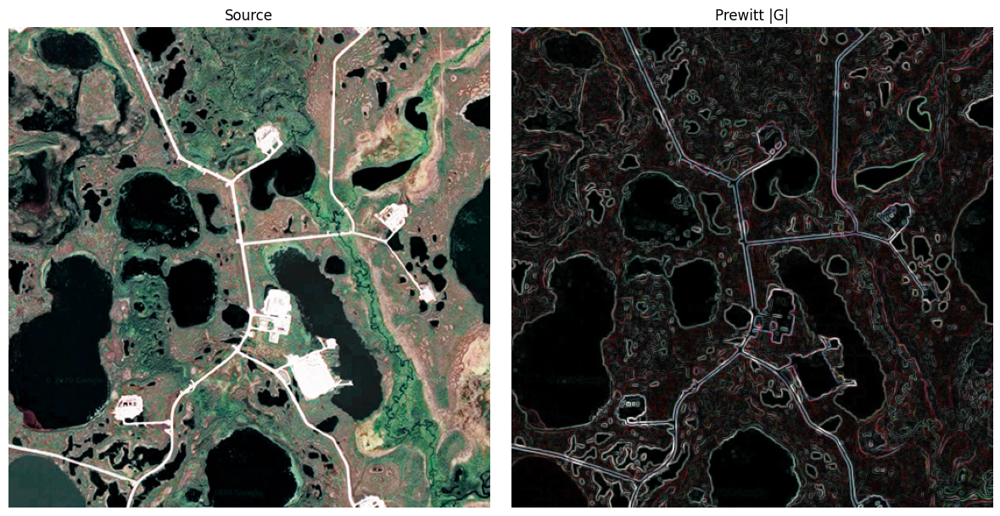

In [10]:
show_pair(img, apply_filter(img, kernel_vertical, mode="abs"),   "Source", "Vertical edges (Sobel X)")
show_pair(img, apply_filter(img, kernel_horizontal, mode="abs"), "Source", "Horizontal edges (Sobel Y)")
show_pair(img, apply_filter(img, kernel_diag45, mode="abs"),     "Source", "Diagonal edges")
show_pair(img, prewitt_magnitude(img),                           "Source", "Prewitt |G|")

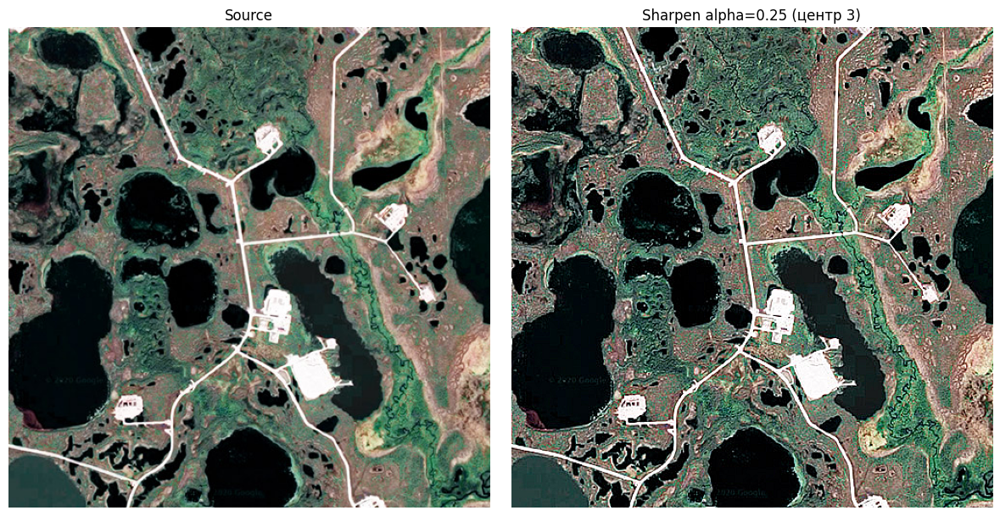

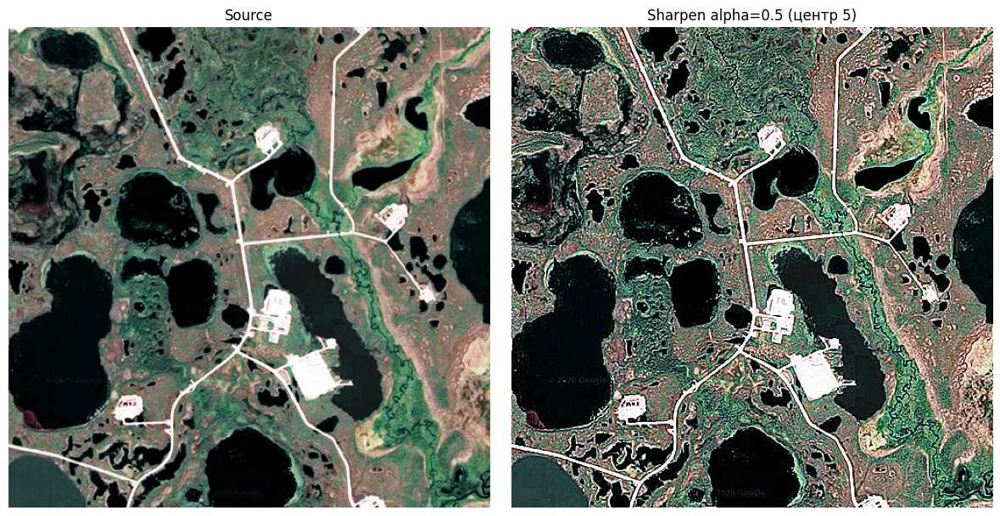

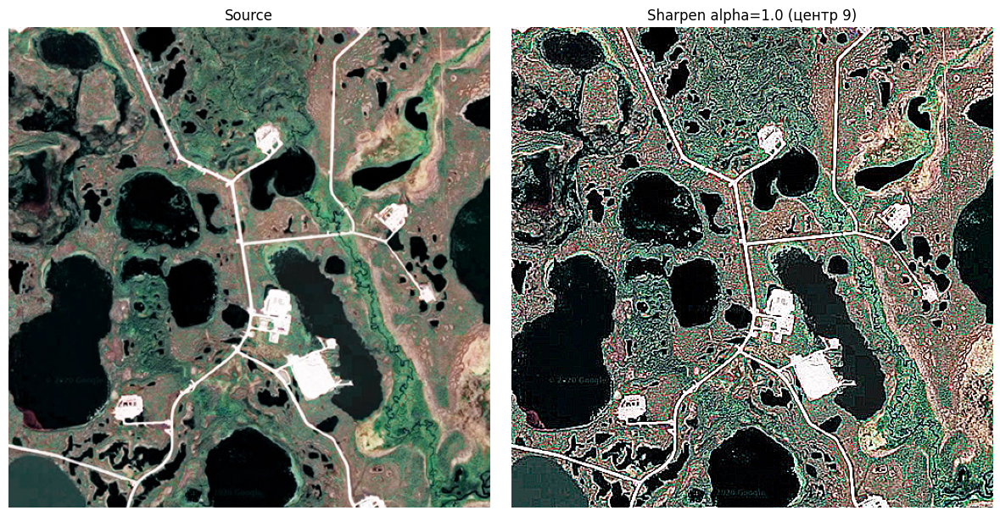

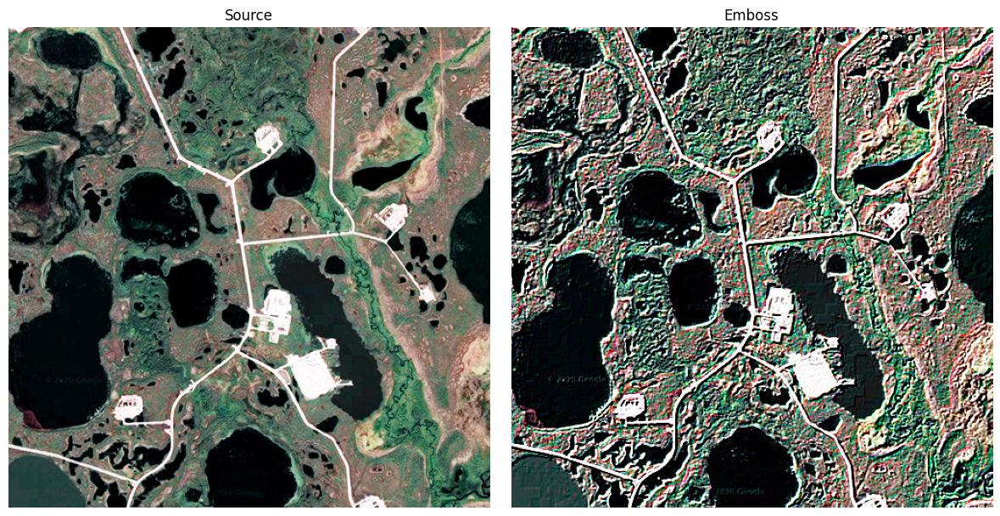

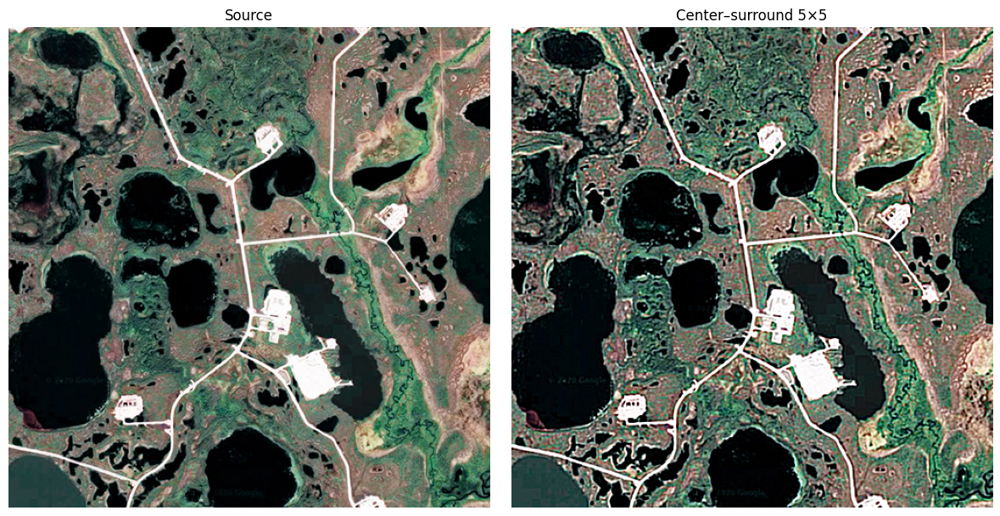

In [11]:
for alpha in (0.25, 0.5, 1.0):
    res = apply_filter(img, sharpening_kernel(alpha))
    show_pair(img, res, "Source", f"Sharpen alpha={alpha} (центр {1 + 8 * alpha:g})")

# Тиснение: результат сразу в uint8. Прибавлять 128 к uint8 нельзя —
# значения выше 255 «перепрыгивают» через ноль (переполнение uint8)
show_pair(img, apply_filter(img, kernel_emboss), "Source", "Emboss")
show_pair(img, apply_filter(img, kernel_center_surround), "Source", "Center–surround 5×5")

### Назначение собственных ядер

| Ядро | Назначение | Пример применения |
|---|---|---|
| **Vertical (Собель X)** | Выделение вертикальных границ | Столбцы таблиц, рамки документов, штрих-коды, дороги «север–юг» на снимках |
| **Horizontal (Собель Y)** | Выделение горизонтальных границ | Строки текста, подчёркивания, дороги «запад–восток» |
| **Diagonal** | Выделение диагональных границ (сильнее всего «\») | Чертежи, схемы, наклонные дороги и разметка |
| **Prewitt \|G\|** | Детектор границ любой ориентации (модуль градиента по X и Y) | Контуры объектов, подготовка к выделению контуров и сегментации |
| **Sharpen (alpha=0.25/0.5/1)** | Повышение резкости с регулируемой силой | Улучшение читаемости сканов, чёткость снимков |
| **Emboss** | Псевдообъёмный рельеф | Художественная стилизация, визуальная оценка рельефа |
| **Center–surround 5×5** | Усиление мелких деталей и точечных объектов на фоне | Небольшие строения, точечные цели на снимках |

### Экспериментальные наблюдения

- Ядра повышения резкости имеют сумму 1, поэтому средняя яркость сохраняется. `alpha=0.25` (центр 3) — мягкое повышение резкости; `alpha=0.5` (центр 5) — заметное; `alpha=1.0` (классическое ядро с центром 9) — сильное, появляются ореолы вокруг дорог и площадок и усиливается шум.
- Ядра Собеля по X и Y разделяют направления: на дорогах «север–юг» откликается вертикальное ядро, на дорогах «запад–восток» — горизонтальное. Без модуля (`mode="clip"`) была бы видна только одна сторона каждой дороги.
- Диагональное ядро сильнее реагирует на границы, идущие по диагонали «\», но из-за малого размера (3×3) частично откликается и на другие направления.
- Модуль градиента Превитта выделяет границы любой ориентации — это универсальный детектор.
- **Emboss** создаёт эффект рельефа: края подсвечиваются с одной стороны и затемняются с другой.
- **Center–surround** одинаково усиливает края и углы любой ориентации, поэтому для поиска именно прямых углов не подходит; для этого нужны специальные методы (например, детектор Харриса `cv2.cornerHarris`).

## 5. Итоговый отчёт

### Цель работы
Изучить метод 2D-свёртки (`cv2.filter2D`) и применить его для фильтрации изображений, реализовать пользовательские ядра для прикладных задач.

### Ход работы
1. Загружены изображения из папки `Изображения` (5 космоснимков в формате JPG).
2. Применены фильтры низких и высоких частот из методички, результаты сохранены в `Результаты` (`N_low.jpg`, `N_high.jpg`).
3. Проведено сравнение исходных и обработанных изображений по каждому снимку, в том числе на увеличенных фрагментах.
4. Разработаны и протестированы 7 пользовательских ядер на фрагменте снимка `4.jpg`.

### Основные результаты

**Фильтр низких частот (усредняющий 5×5):**
- Сглаживает изображение, удаляет шум, размывает границы.
- Хорошо выделяет крупные однородные области (водоёмы, лесные массивы, поля, крупные формы рельефа).
- Применение: шумоподавление, подготовка к бинаризации, размытие.

**Фильтр высоких частот (лапласиан 3×3):**
- Выделяет контуры, границы и текстуры; однородные области становятся чёрными.
- Ярче всего проявляются дороги, улицы, застройка, береговые линии; вместе с ними усиливается шум.
- Применение: выделение границ, повышение резкости, анализ текстуры.

**Собственные ядра:**
- Позволяют решать узкоспециализированные задачи: выделение границ заданного направления (Собель), границ любой ориентации (модуль градиента Превитта), регулируемое повышение резкости, стилизацию.
- Для ядер с суммой 0 важно учитывать знак отклика: считать во float и брать модуль, иначе при записи в `uint8` теряется половина границ.
- Для ядер с суммой 1 яркость сохраняется; прибавление констант к `uint8` без приведения типа приводит к переполнению.

### Общий вывод
Свёртка — фундаментальный инструмент обработки изображений. Комбинируя размер и веса ядра, можно решать задачи сглаживания, выделения границ, повышения резкости и стилизации. Низкочастотные фильтры используются для сглаживания и подготовки данных, высокочастотные — для анализа структуры и выделения линейных объектов. Пользовательские ядра дают возможность тонкой настройки фильтра под конкретную задачу.

### Примечание по чтению файлов
Для корректной работы с путями, содержащими кириллицу (`Изображения`, `Результаты`), вместо `cv2.imread`/`cv2.imwrite` используются обёртки `imread_unicode`/`imwrite_unicode`, основанные на `np.fromfile` + `cv2.imdecode`/`cv2.imencode`. Это решает известную проблему OpenCV на Windows, при которой стандартный `cv2.imread` возвращает `None` для путей с не-ASCII символами.